In [13]:
import numpy as np
import pandas as pd
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense
from keras.optimizers import Adam
from keras.layers import Dropout
from keras import regularizers
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,MinMaxScaler
from tensorflow.keras.callbacks import EarlyStopping # type: ignore
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder

In [14]:
file_path = r'C:\Users\Maste\Downloads\mold_dataset_balanced.csv'
dataset = pd.read_csv(file_path)

In [15]:
X = dataset.drop(columns=['mold_risk_category','timestamp', 'date'])
y = dataset['mold_risk_category']

In [16]:
# Create a label encoder and transform string labels to integers
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Get number of classes and print the mapping of labels
num_classes = len(np.unique(y_encoded))
print(f"Number of classes: {num_classes}")
print(f"Class labels mapping: {dict(zip(label_encoder.classes_, range(num_classes)))}")

# Convert class vector to binary class matrices (one-hot encoding)
y_categorical = to_categorical(y_encoded, num_classes=num_classes)

# Scale features before train_test_split
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_categorical, test_size=0.2, random_state=42)

Number of classes: 3
Class labels mapping: {'High': 0, 'Low': 1, 'Moderate': 2}


In [17]:
# Define the model
model = tf.keras.models.Sequential([
    tf.keras.layers.Dense(16, activation='relu', input_shape=(X_train.shape[1],)),  # Input layer
    tf.keras.layers.Dropout(0.3),  # Dropout layer after the input layer (30% dropout rate)
    
    tf.keras.layers.Dense(8, activation='relu'),  # Hidden layer
    tf.keras.layers.Dropout(0.3),  # Dropout layer after the hidden layer (30% dropout rate)
    tf.keras.layers.Dense(4, activation='relu'),
    tf.keras.layers.Dense(len(y.unique()), activation='softmax')  # Output layer (Multi-class Classification)
])

C:\Users\Maste\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\core\dense.py:92: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [18]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            15 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 267 (1.04 KB)

 Trainable params: 267 (1.04 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
adam = Adam(learning_rate=0.001)

In [20]:
model.compile(optimizer=adam, loss='categorical_crossentropy', metrics=['accuracy'])

In [21]:
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

In [22]:
history = model.fit(X_train, y_train, epochs=50, batch_size=32, validation_data=(X_test, y_test), verbose=1)

Epoch 1/50
5264/5264 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.9372 - loss: 0.1871 - val_accuracy: 0.9996 - val_loss: 0.0043
5264/5264 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.9372 - loss: 0.1871 - val_accuracy: 0.9996 - val_loss: 0.0043
Epoch 2/50
Epoch 2/50
5264/5264 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step - accuracy: 0.9854 - loss: 0.0466 - val_accuracy: 1.0000 - val_loss: 0.0015
Epoch 3/50
5264/5264 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step - accuracy: 0.9854 - loss: 0.0466 - val_accuracy: 1.0000 - val_loss: 0.0015
Epoch 3/50
5264/5264 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - accuracy: 0.9868 - loss: 0.0330 - val_accuracy: 1.0000 - val_loss: 4.6544e-04
Epoch 4/50
5264/5264 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - accuracy: 0.9868 - loss: 0.0330 - val_accuracy: 1.0000 - val_loss: 4.6544e-04
Epoch 4/50
5264/5264 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step - accuracy: 0.9874 - loss: 0.0260 - val_accuracy: 1.0000 - val_loss: 2.0403e-04
Epoch 5/50
5264/5264 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step - accuracy: 0.9874 - l

KeyboardInterrupt: 

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.4f}")

1316/1316 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9995 - loss: 0.0016
Test Loss: 0.0016, Test Accuracy: 0.9995
1316/1316 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9995 - loss: 0.0016
Test Loss: 0.0016, Test Accuracy: 0.9995


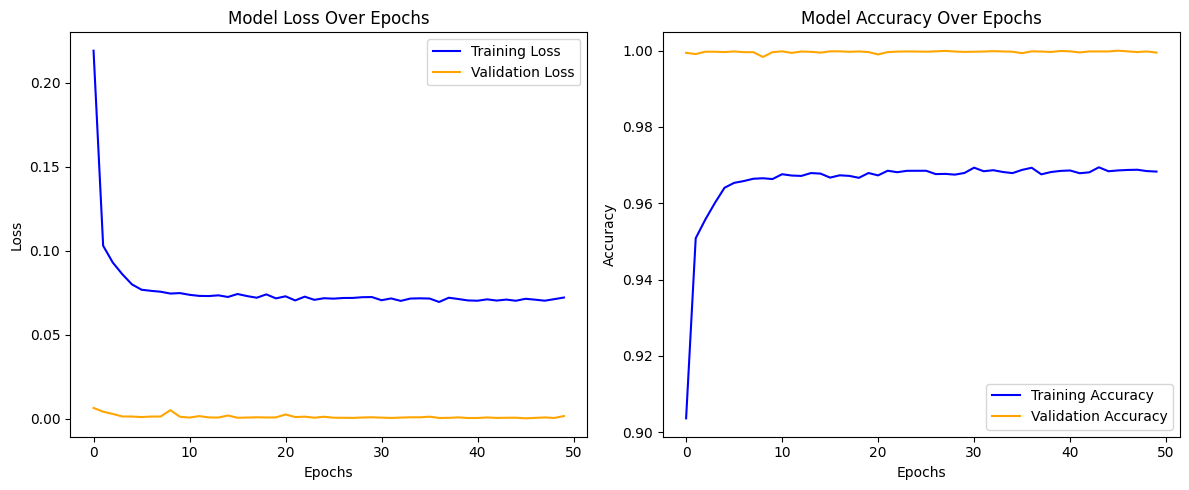

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss', color='blue')
plt.plot(history.history['val_loss'], label='Validation Loss', color='orange')
plt.title('Model Loss Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy', color='blue')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange')
plt.title('Model Accuracy Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import classification_report

# Generate predictions
y_pred_prob = model.predict(X_test)
y_pred_classes = np.argmax(y_pred_prob, axis=1)
y_test_classes = np.argmax(y_test, axis=1)

# Generate classification report
class_names = [str(i) for i in range(num_classes)]  # Adjust based on your actual class names
report = classification_report(y_test_classes, y_pred_classes, target_names=class_names)
print(report)

1316/1316 ━━━━━━━━━━━━━━━━━━━━ 1s 632us/step
1316/1316 ━━━━━━━━━━━━━━━━━━━━ 1s 632us/step
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     13971
           1       1.00      1.00      1.00     14062
           2       1.00      1.00      1.00     14073

    accuracy                           1.00     42106
   macro avg       1.00      1.00      1.00     42106
weighted avg       1.00      1.00      1.00     42106

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     13971
           1       1.00      1.00      1.00     14062
           2       1.00      1.00      1.00     14073

    accuracy                           1.00     42106
   macro avg       1.00      1.00      1.00     42106
weighted avg       1.00      1.00      1.00     42106



In [ ]:
# Convert the model to TensorFlow Lite format
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

# Save the TensorFlow Lite model to a file
tflite_model_path = "prediction.tflite"
with open(tflite_model_path, "wb") as f:
    f.write(tflite_model)

print(f"TensorFlow Lite model saved to {tflite_model_path}")

INFO:tensorflow:Assets written to: C:\Users\Maste\AppData\Local\Temp\tmpcnd7wnf6\assets


INFO:tensorflow:Assets written to: C:\Users\Maste\AppData\Local\Temp\tmpcnd7wnf6\assets


INFO:tensorflow:Assets written to: C:\Users\Maste\AppData\Local\Temp\tmpcnd7wnf6\assets


INFO:tensorflow:Assets written to: C:\Users\Maste\AppData\Local\Temp\tmpcnd7wnf6\assets


Saved artifact at 'C:\Users\Maste\AppData\Local\Temp\tmpcnd7wnf6'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 4), dtype=tf.float32, name='keras_tensor_21')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  2352095231440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2352095224720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2352095230480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2352095223952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2352095231824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2352095227984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2352095224528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2352095229904: TensorSpec(shape=(), dtype=tf.resource, name=None)
TensorFlow Lite model saved to prediction.tflite
TensorFlow Lite model saved to prediction.tflite


In [ ]:
with open("prediction.tflite", "rb") as f:
    tflite_model = f.read()

# Convert to a C-style byte array
c_array = ', '.join(f'0x{b:02x}' for b in tflite_model)
with open("model_data.h", "w") as f:
    f.write(f"const unsigned char tflite_model[] = {{ {c_array} }};\n")
    f.write(f"const unsigned int tflite_model_len = {len(tflite_model)};")